Praktikum 1 - Klasifikasi SVM dengan Data Dummy Linier.

Menampilkan data dummy terpisah linier, ilustrasi margin, fitting SVM kernel
linear (C besar = hard margin), lalu efek jumlah data terhadap support vector.
Output gambar: output/*.png

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("svm_linier.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js11-klasifikasi-2\praktikum-1


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)
rng = np.random.RandomState(0)

[data] X=(50, 2) y=(50,) kelas=[25 25]
[margin] 3 kandidat garis (m,b,d) digambar
[svm] akurasi latih = 1.0000
[svm] jumlah support vector = 3 dari 50 data
[svm] support_vectors_ =
 [[0.443599 3.115309]
 [2.338123 3.431168]
 [2.061568 1.969186]]


[N] SV N=60: 3, N=120: 3 (garis keputusan praktis sama)
[selesai] praktikum 1


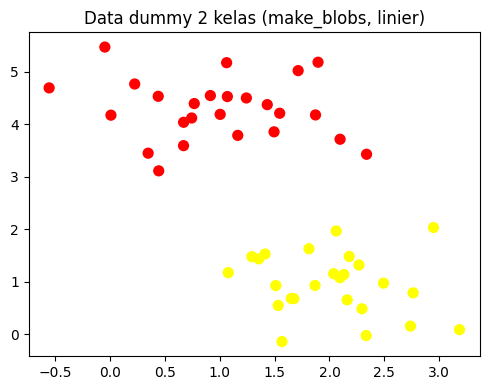

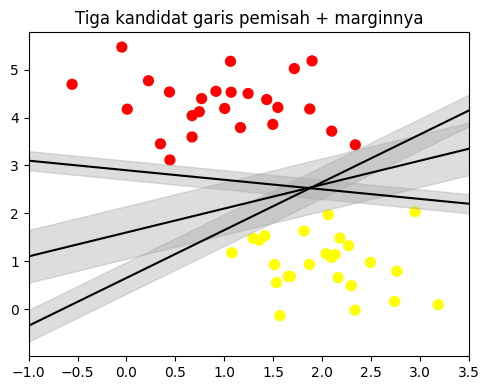

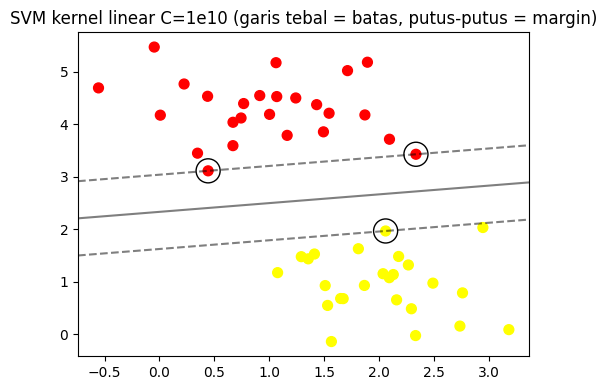

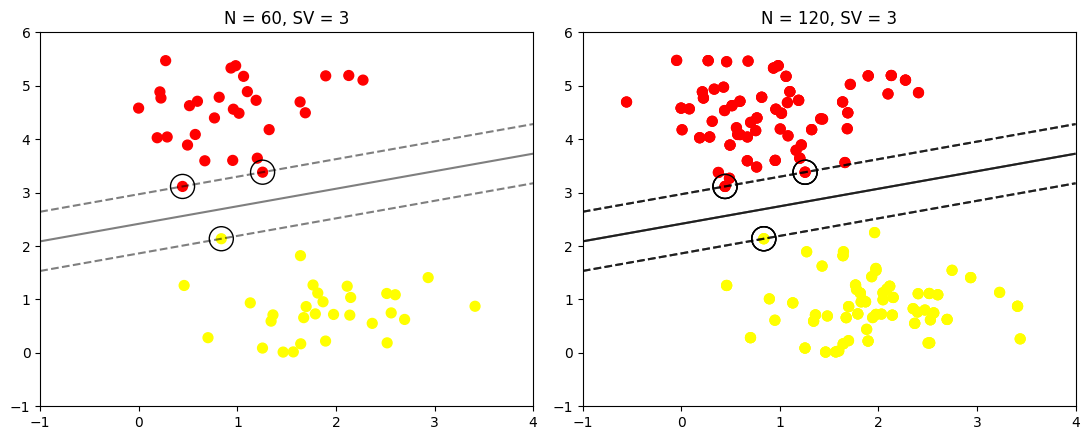

In [3]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    """Gambar garis keputusan + margin + lingkaran support vector."""
    if ax is None:
        ax = plt.gca()
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    ax.contour(X, Y, P, colors="k", levels=[-1, 0, 1], alpha=0.5,
               linestyles=["--", "-", "--"])
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors="none", edgecolors="k")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


# --- Langkah 2: data dummy linier -------------------------------------------
X, y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap="autumn")
ax.set_title("Data dummy 2 kelas (make_blobs, linier)")
fig.tight_layout()
fig.savefig(OUT / "01_data_dummy.png", dpi=110)
print(f"[data] X={X.shape} y={y.shape} kelas={np.bincount(y)}")

# --- Langkah 4: ilustrasi beberapa garis + margin ---------------------------
xfit = np.linspace(-1, 3.5)
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap="autumn")
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    ax.plot(xfit, yfit, "-k")
    ax.fill_between(xfit, yfit - d, yfit + d, edgecolor="none",
                    color="#AAAAAA", alpha=0.4)
ax.set_xlim(-1, 3.5)
ax.set_title("Tiga kandidat garis pemisah + marginnya")
fig.tight_layout()
fig.savefig(OUT / "02_margin_kandidat.png", dpi=110)
print("[margin] 3 kandidat garis (m,b,d) digambar")

# --- Langkah 5: fitting SVM kernel linear, C sangat besar -------------------
model = SVC(kernel="linear", C=1e10)
model.fit(X, y)
print(f"[svm] akurasi latih = {accuracy_score(y, model.predict(X)):.4f}")
print(f"[svm] jumlah support vector = {len(model.support_vectors_)} dari {len(X)} data")
print("[svm] support_vectors_ =\n", np.round(model.support_vectors_, 6))

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap="autumn")
plot_svc_decision_function(model, ax)
ax.set_title("SVM kernel linear C=1e10 (garis tebal = batas, putus-putus = margin)")
fig.tight_layout()
fig.savefig(OUT / "03_decision_boundary.png", dpi=110)


# --- Efek jumlah data: 60 vs 120 -------------------------------------------
def plot_svm(N=10, ax=None):
    Xd, yd = make_blobs(n_samples=200, centers=2, random_state=0, cluster_std=0.60)
    Xd, yd = Xd[:N], yd[:N]
    m = SVC(kernel="linear", C=1e10).fit(Xd, yd)
    ax = ax or plt.gca()
    ax.scatter(Xd[:, 0], Xd[:, 1], c=yd, s=50, cmap="autumn")
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(m, ax)
    return m


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axi, N in zip(axes, [60, 120]):
    m = plot_svm(N, axi)
    axi.set_title(f"N = {N}, SV = {len(m.support_vectors_)}")
fig.tight_layout()
fig.savefig(OUT / "04_efek_jumlah_data.png", dpi=110)
m60, m120 = plot_svm(60), plot_svm(120)
print(f"[N] SV N=60: {len(m60.support_vectors_)}, N=120: {len(m120.support_vectors_)} "
      "(garis keputusan praktis sama)")
print("[selesai] praktikum 1")